# Exp 6 — HN weight divergence (TaskDist 1–3)

Latest RNN+HN weight-div runs (`td*_6_randstart`):
- **Env:** 6×6 GridNavi, dense Manhattan, **random start**
- **Metric:** mean pairwise L2 of per-goal mean actor HN weights
- **Data:** TensorBoard exports in `hyper/logs/weightdiv/td{1,2,3}_randstart.csv`

Also visualise the three goal supports (same layout style as exp2).

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

CODE_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
WEIGHTDIV_DIR = CODE_DIR / "hyper" / "logs" / "weightdiv"

NUM_CELLS = 6  # matches latest weight-div experiment
print("CODE_DIR:", CODE_DIR)
print("WEIGHTDIV_DIR:", WEIGHTDIV_DIR, "exists=", WEIGHTDIV_DIR.is_dir())

CODE_DIR: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex
WEIGHTDIV_DIR: /Users/maheshgondi/Documents/IITM/7/Adv_RL/hypex/hyper/logs/weightdiv exists= True


## Goal supports (TaskDist 1–3)

Same `goal_positions` definition as exp2, evaluated on a **6×6** grid.

In [2]:
def goal_positions(option, num_cells):
    if option == 1:
        # top-right corner cluster
        pos = [
            (num_cells - 1, num_cells - 1),
            (num_cells - 1, num_cells - 2),
            (num_cells - 2, num_cells - 1),
            (num_cells - 2, num_cells - 2),
        ]
    elif option == 2:
        # mid / edge spread
        pos = [
            (num_cells // 2, num_cells // 2),
            (num_cells - 1, num_cells // 2),
            (num_cells // 2, num_cells - 1),
            (num_cells - 1, num_cells - 1),
        ]
    elif option == 3:
        # four corners
        pos = [
            (0, 0),
            (0, num_cells - 1),
            (num_cells - 1, 0),
            (num_cells - 1, num_cells - 1),
        ]
    else:
        raise ValueError(f"Unknown goal_positions option: {option}")
    return pos


task_dists = {
    1: goal_positions(1, NUM_CELLS),
    2: goal_positions(2, NUM_CELLS),
    3: goal_positions(3, NUM_CELLS),
}

for dist_id, goals in task_dists.items():
    print(f"TD{dist_id}: {goals}")

TD1: [(5, 5), (5, 4), (4, 5), (4, 4)]
TD2: [(3, 3), (5, 3), (3, 5), (5, 5)]
TD3: [(0, 0), (0, 5), (5, 0), (5, 5)]


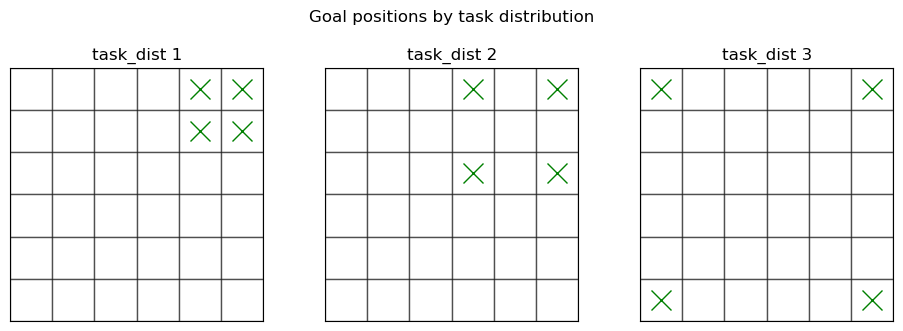

In [3]:
# visualise goal positions for each task distribution (exp2 style)

n = len(task_dists)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.2 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, (dist_id, goals) in zip(axes, task_dists.items()):
    for x in range(NUM_CELLS):
        for y in range(NUM_CELLS):
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor="w", alpha=0.5, edgecolor="k"))

    for gx, gy in goals:
        ax.plot(gx + 0.5, NUM_CELLS - gy - 1 + 0.5, "gx", markersize=14, zorder=5)

    ax.set_xlim(0, NUM_CELLS)
    ax.set_ylim(NUM_CELLS, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"task_dist {dist_id}")

for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    f"Goal positions by task distribution",
    y=1.02,
)
fig.tight_layout()
plt.show()

## Weight divergence curves

CSV columns from TensorBoard: `Wall time`, `Step` (PPO update), `Value` (`hn_weight_div/mean_pairwise_l2`).

In [4]:
# CSVs were briefly misnamed (td1↔td3); files on disk are corrected.
# Fingerprints vs run logs:
#   TD1 (top-right): ~0.55 @500 → ~3.89 @15500
#   TD2 (mid/edge):  ~1.37 @500 → ~4.33 @15500
#   TD3 (corners):   ~4.95 @500 → ~7.68 @15500
CSV_BY_DIST = {
    1: WEIGHTDIV_DIR / "td1_randstart.csv",
    2: WEIGHTDIV_DIR / "td2_randstart.csv",
    3: WEIGHTDIV_DIR / "td3_randstart.csv",
}

curves = {}
for dist_id, path in CSV_BY_DIST.items():
    if not path.is_file():
        raise FileNotFoundError(path)
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    step_col = cols.get("step") or cols.get("steps")
    val_col = cols.get("value") or cols.get("mean_pairwise_l2")
    if step_col is None or val_col is None:
        raise ValueError(f"{path.name}: unexpected columns {list(df.columns)}")
    curves[dist_id] = df[[step_col, val_col]].rename(
        columns={step_col: "step", val_col: "mean_pairwise_l2"}
    ).sort_values("step")
    print(f"TD{dist_id}: {path.name}  n={len(curves[dist_id])}  "
          f"step[{curves[dist_id]['step'].iloc[0]}…{curves[dist_id]['step'].iloc[-1]}]  "
          f"final D={curves[dist_id]['mean_pairwise_l2'].iloc[-1]:.4f}")

TD1: td1_randstart.csv  n=31  step[500…15500]  final D=3.8881
TD2: td2_randstart.csv  n=31  step[500…15500]  final D=4.3270
TD3: td3_randstart.csv  n=31  step[500…15500]  final D=7.6801


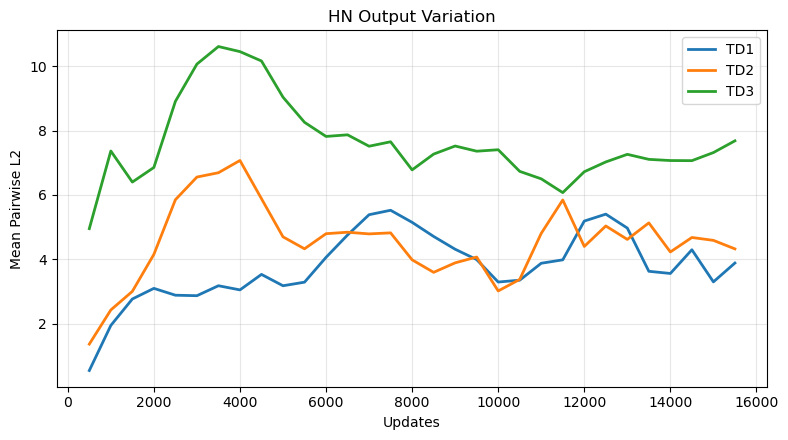

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))

labels = {
    1: "TD1",
    2: "TD2",
    3: "TD3",
}

for dist_id, df in curves.items():
    ax.plot(
        df["step"],
        df["mean_pairwise_l2"],
        label=labels[dist_id],
        linewidth=2,
    )

ax.set_xlabel("Updates")
ax.set_ylabel("Mean Pairwise L2")
ax.set_title("HN Output Variation")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [6]:
# final / late-training summary
rows = []
for dist_id, df in curves.items():
    rows.append({
        "dist": dist_id,
        "goals": task_dists[dist_id],
        "final_step": int(df["step"].iloc[-1]),
        "final_D": float(df["mean_pairwise_l2"].iloc[-1]),
        "max_D": float(df["mean_pairwise_l2"].max()),
        "mean_last_5": float(df["mean_pairwise_l2"].tail(5).mean()),
    })
summary = pd.DataFrame(rows).set_index("dist")
display(summary)

,goals,final_step,final_D,max_D,mean_last_5
dist,,,,,
1,"[(5, 5), (5, 4), (4, 5), (4, 4)]",15500,3.888082,5.525312,3.737362
2,"[(3, 3), (5, 3), (3, 5), (5, 5)]",15500,4.326999,7.070142,4.592868
3,"[(0, 0), (0, 5), (5, 0), (5, 5)]",15500,7.680144,10.606301,7.246793
